In [1]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision/stats/xReceiver
/Users/svasquez/driblab/dl-vision


# 1. Setup & Load Data

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [7]:
# load data

path = f"stats/pitch_control/dfs/model_df_pitch_control.csv" # for local
path = f"stats/xReceiver/data/xR_training_data_v1.csv" # for local

# path = f"/content/model_df_pitch_control.csv" # for colab

df = pd.read_csv(path)

print(f"Length of df: {len(df)}")

Length of df: 1711079


In [8]:
errors_df = pd.read_csv("stats/xReceiver/data/errors_xR_model_v1.csv")

print(f"ERRORS: {errors_df['error_count'].sum()}")

ERRORS: 0


## See unique match ids

In [9]:
unique_match_ids = df['match_id'].unique()
print(f"Number of unique match ids: {len(unique_match_ids)}")

Number of unique match ids: 220


## See unique Event ids

In [10]:
unique_event_ids = df['event_id'].unique()
print(f"Number of unique event ids: {len(unique_event_ids)}")

Number of unique event ids: 171285


# Inspect Target Distribution

In [11]:
# See targe label distribution
print(df['target'].value_counts())

0    1540674
1     170405
Name: target, dtype: int64


Notice a class imbalance: many more negative samples (not receivers) than positive ones (true receivers).

# Balance the Dataset

We keep all true receivers (target == 1) and sample up to k=3 negative candidates per event:

In [12]:
# Drop Na
df = df.dropna()

from sklearn.model_selection import train_test_split

# Get unique event_ids and split
event_ids = df['event_id'].unique()
train_ids, test_ids = train_test_split(event_ids, test_size=0.2, random_state=42)

# Split full df (not sampled yet)
df_train_full = df[df['event_id'].isin(train_ids)].copy()
df_test = df[df['event_id'].isin(test_ids)].copy()

# Train-Test Split by Event

We ensure no event is split across train and test:texto en negrita

In [13]:
# Keep all positives in train
df_positive = df_train_full[df_train_full['target'] == 1]

# Sample k negatives per event
top_k = 3
negatives = df_train_full[df_train_full['target'] == 0]
negatives_sampled = negatives.groupby('event_id').apply(
    lambda g: g.sample(n=min(len(g), top_k), random_state=42)
).reset_index(drop=True)

# Combine positives and sampled negatives
df_train = pd.concat([df_positive, negatives_sampled], axis=0).sample(frac=1, random_state=42)

## Make sure that the test set is not down sampled

In [14]:
# Group by event_id and count rows
avg_rows_per_events = df_test.groupby('event_id').size()

# Compute the average
avg_rows = avg_rows_per_events.mean()

print(f"Average number of examples per event in test set: {avg_rows:.2f}")

Average number of examples per event in test set: 9.70


In [15]:
# Group by event_id and count rows
avg_rows_per_events = df_train.groupby('event_id').size()

# Compute the average
avg_rows = avg_rows_per_events.mean()

print(f"Average number of examples per event in train set: {avg_rows:.2f}")

Average number of examples per event in train set: 3.97


# Prepare Features

In [16]:
feature_cols = df_train.drop(columns=['target', 'match_id', 'row_num', 'giver_id', 'receiver_id']).columns

X_train = df_train[feature_cols].copy()
y_train = df_train['target']

X_test = df_test[feature_cols].copy()
y_test = df_test['target']

# Train XGBoost Classifier

In [17]:

from xgboost import XGBClassifier
# Calculate the ratio of negatives to positives in the training set
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

clf = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    verbosity=1,
    use_label_encoder=False,
    eval_metric='logloss',
    tree_method='hist',
    scale_pos_weight=neg_pos_ratio  # <-- this helps a lot
)

clf.fit(X_train.drop(columns=['event_id']), y_train)

/Users/svasquez/driblab/dl-vision/.venv/lib/python3.8/site-packages/xgboost/core.py:158: UserWarning: [22:43:22] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

# Evaluation

Since we are trying to predict which player is most likely to receive a pass at a given moment. For each event (i.e., a pass attempt), there are multiple possible receivers — typically 10 outfield teammates.

Instead of only evaluating whether the model’s top prediction is correct (Top-1 accuracy), we use Top-k Accuracy to check if the true receiver is within the top k predicted players. This is more reflective of the real-world use case in football analytics, where:
	•	There can be multiple plausible receiving options.
	•	Analysts or decision-makers may want a shortlist of top options, not just one.
	•	Ranked probabilities are more valuable than binary predictions.

Top-k accuracy is particularly useful for assessing how well the model prioritizes the true target among all possible candidates.

In [18]:
def top_k_accuracy(df_probs, k=3):
    correct = 0
    total = 0
    for event_id, group in df_probs.groupby('event_id'):
        top_k = group.sort_values('pred_prob', ascending=False).head(k)
        if top_k['target'].any():
            correct += 1
        total += 1
    return correct / total

In [19]:
df_test['pred_prob'] = clf.predict_proba(X_test.drop(columns=['event_id']))[:, 1]

print(f"Top-1 Accuracy: {top_k_accuracy(df_test, k=1):.4f}")
print(f"Top-3 Accuracy: {top_k_accuracy(df_test, k=3):.4f}")

Top-1 Accuracy: 0.2617
Top-3 Accuracy: 0.5501


In [21]:
print(f"Top-5 Accuracy: {top_k_accuracy(df_test, k=5):.4f}")

Top-5 Accuracy: 0.7272


In [74]:
# Standard metrics
from sklearn.metrics import classification_report, roc_auc_score

y_pred = clf.predict(X_test.drop(columns=['event_id']))
y_pred_prob = df_test['pred_prob']

print(classification_report(y_test, y_pred))
print(f"AUC-ROC Score: {roc_auc_score(y_test, y_pred_prob):.4f}")

              precision    recall  f1-score   support

           0       0.94      0.66      0.78    290792
           1       0.17      0.63      0.27     32356

    accuracy                           0.66    323148
   macro avg       0.56      0.64      0.52    323148
weighted avg       0.86      0.66      0.73    323148

AUC-ROC Score: 0.7039


## Feature IMportance

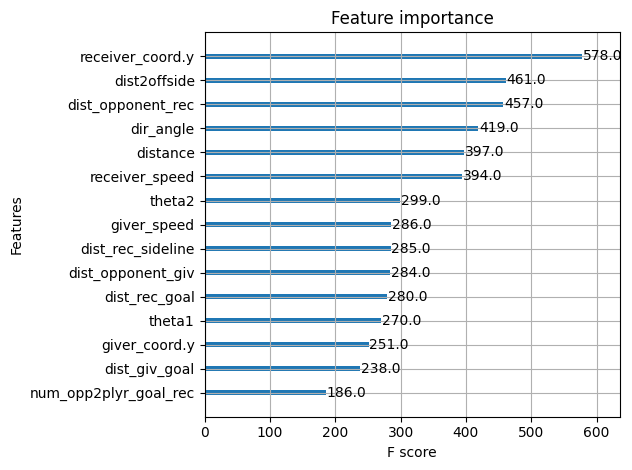

In [75]:
import matplotlib.pyplot as plt
import xgboost as xgb

xgb.plot_importance(clf, max_num_features=15)
plt.tight_layout()
plt.show()

# Hyperparameter tuning

In [76]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 1, 5],  # regularization
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 5, 10]
}


In [77]:
from sklearn.model_selection import RandomizedSearchCV

# Set up the classifier
clf = XGBClassifier(
    random_state=42,
    # use_label_encoder=False,
    eval_metric='logloss',
    tree_method='hist',
    scale_pos_weight=neg_pos_ratio
)

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=30,  # try 30 random combinations
    scoring='roc_auc',  # or 'f1', or custom Top-1 Accuracy scorer
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1  # use all cores
)

# Fit
random_search.fit(X_train.drop(columns=['event_id']), y_train)


Fitting 3 folds for each of 30 candidates, totalling 90 fits
[CV] END colsample_bytree=0.8, gamma=5, learning_rate=0.1, max_depth=6, n_estimators=300, reg_alpha=0, reg_lambda=10, subsample=0.8; total time=  16.0s
[CV] END colsample_bytree=0.8, gamma=5, learning_rate=0.1, max_depth=6, n_estimators=300, reg_alpha=0, reg_lambda=10, subsample=0.8; total time=  16.0s
[CV] END colsample_bytree=0.8, gamma=5, learning_rate=0.1, max_depth=6, n_estimators=300, reg_alpha=0, reg_lambda=10, subsample=0.8; total time=  16.2s
[CV] END colsample_bytree=0.6, gamma=0, learning_rate=0.1, max_depth=8, n_estimators=200, reg_alpha=1, reg_lambda=5, subsample=1.0; total time=  16.4s
[CV] END colsample_bytree=0.6, gamma=0, learning_rate=0.1, max_depth=8, n_estimators=200, reg_alpha=1, reg_lambda=5, subsample=1.0; total time=  16.5s
[CV] END colsample_bytree=0.6, gamma=0, learning_rate=0.1, max_depth=8, n_estimators=200, reg_alpha=1, reg_lambda=5, subsample=1.0; total time=  17.1s
[CV] END colsample_bytree=0.8,

RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='logloss',
                                           feature_types=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraints=None,
                                           learning...
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None,
                                           random_state=42, ...),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.6, 0.8, 1.0],
                                        'gamma': [0, 1, 5],
                                        'learning_rate': [0.01, 0.05, 0.1, 0.2],
                                        'max_depth': [4, 6, 8, 10],
                                        'n_estimators': [100, 200, 300],
                                        'reg_alpha': [0, 0.1, 1],
                                        'reg_lambda': [1, 5, 10],
                                        'subsample': [0.6, 0.8, 1.0]},
                   random_state=42, scoring='roc_auc', verbose=2)

In [78]:
print("Best parameters found: ", random_search.best_params_)
print("Best AUC score: ", random_search.best_score_)

best_model = random_search.best_estimator_


Best parameters found:  {'subsample': 0.8, 'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8}
Best AUC score:  0.7071913642497529


In [79]:
import pickle

with open("/Users/svasquez/driblab/dl-vision/stats/xReceiver/models/xgb_model_no_pc.pkl", "wb") as f:
    pickle.dump(best_model, f)


# Save model

In [91]:
import joblib
joblib.dump(clf, 'xgb_model.pkl')
# Later: clf = joblib.load('xgb_model.pkl')

['xgb_model.pkl']

# Try other models

## Random Forest

In [80]:
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators=100, class_weight='balanced')
clf.fit(X_train.drop(columns=['event_id']), y_train)

df_test['pred_prob'] = clf.predict_proba(X_test.drop(columns=['event_id']))[:, 1]

print(f"Top-1 Accuracy: {top_k_accuracy(df_test, k=1):.4f}")
print(f"Top-3 Accuracy: {top_k_accuracy(df_test, k=3):.4f}")

y_pred = clf.predict(X_test.drop(columns=['event_id']))
y_pred_prob = df_test['pred_prob']

print(classification_report(y_test, y_pred))
print(f"AUC-ROC Score: {roc_auc_score(y_test, y_pred_prob):.4f}")



Top-1 Accuracy: 0.2567
Top-3 Accuracy: 0.5428
              precision    recall  f1-score   support

           0       0.91      0.98      0.94    290792
           1       0.38      0.11      0.17     32356

    accuracy                           0.89    323148
   macro avg       0.64      0.54      0.56    323148
weighted avg       0.85      0.89      0.87    323148

AUC-ROC Score: 0.6983


## LightGBM (Gradient Boosting)

In [ ]:
from lightgbm import LGBMClassifier
clf = LGBMClassifier(class_weight='balanced')


## CatBoost

In [ ]:
from catboost import CatBoostClassifier
clf = CatBoostClassifier(verbose=100, scale_pos_weight=neg_pos_ratio)
